修复后实验与独立区间验收

本实验使用 2027–2031 年的合成机队。生成配置、随机种子、实体命名空间与验收门槛在模型冻结时登记；随后生成独立数据并执行一次评分。验收门槛：事件召回率 ≥80%，总体与逐批警报比例 ≤5%，至少 100 个拆换事件。

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
report = root / 'reports/corrected_v2'
metrics = json.loads((report / 'test_metrics.json').read_text(encoding='utf-8'))
freeze = json.loads((report / 'freeze_manifest.json').read_text(encoding='utf-8'))
pd.DataFrame([{'candidate': metrics['candidate_id'], 'events': metrics['actual_unscheduled_events'], 'detected': metrics['detected_events'], 'event_recall': metrics['event_recall'], 'alerts_per_100': metrics['alerts_per_100'], 'over_capacity_batches': metrics['over_capacity_batches'], 'sla_met': metrics['sla_met']}])

,candidate,events,detected,event_recall,alerts_per_100,over_capacity_batches,sla_met
0,logistic_unweighted,393,384,0.977099,0.400814,0,True


独立性与产物关联

新旧数据按实际时点和实体逐项核对；特征、模型、策略及执行源码的身份保存在冻结清单与验收记录中。

In [2]:
evidence = metrics['acceptance_evidence']
assert all(value == 0 for value in evidence['entity_intersections'].values())
assert pd.Timestamp(evidence['previous_latest_snapshot']) < pd.Timestamp(evidence['first_snapshot'])
assert pd.Timestamp(evidence['frozen_at_utc']) < pd.Timestamp(evidence['generated_at_utc'])
assert pd.Timestamp(freeze['policy_latest_used_label']) < pd.Timestamp(freeze['policy_selection_cutoff'])
pd.Series(evidence)

protocol_id                                               independent_2027_v1
protocol_sha256             790dde36f3b8815745fb2cc4036857ace2df28eb98a50d...
data_manifest_sha256        c6fcaa307b1328f65edfb83e21968a7848e2d2c6b9fb12...
data_version                                            0.3.0-acceptance-2027
seed                                                                 20261113
generated_at_utc                             2026-11-13T01:25:15.506158+00:00
frozen_at_utc                                2026-11-13T01:25:10.299196+00:00
previous_latest_snapshot                            2026-12-06T00:00:00+00:00
first_snapshot                                      2027-01-04T18:00:00+00:00
last_snapshot                                       2031-12-06T00:00:00+00:00
entity_intersections        {'aircraft_id': 0, 'component_id': 0, 'install...
aircraft                                                                   60
components                                                      

In [3]:
candidates = pd.read_csv(report / 'validation_candidate_metrics.csv')
candidates[['candidate_id', 'event_recall', 'alerts_per_100', 'false_positives_per_100', 'brier_score', 'threshold']]

,candidate_id,event_recall,alerts_per_100,false_positives_per_100,brier_score,threshold
0,logistic_unweighted,1.0,0.543024,0.0,0.006092,0.999592
1,logistic_balanced,1.0,0.584795,0.0,0.004929,0.999818
2,lightgbm_unweighted,1.0,0.626566,0.0,0.002989,0.988066
3,lightgbm_balanced,1.0,0.584795,0.0,0.002835,0.987123


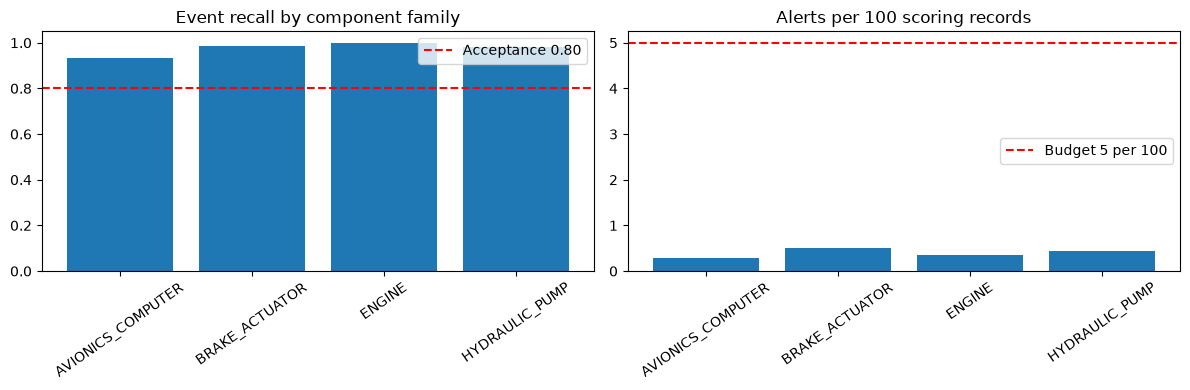

In [4]:
slices = pd.read_csv(report / 'test_slice_metrics.csv')
family = slices[slices.slice_column.eq('component_family')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(family.slice_value, family.event_recall)
axes[0].axhline(.8, color='red', linestyle='--', label='Acceptance 0.80')
axes[0].set(ylim=(0, 1.05), title='Event recall by component family')
axes[0].legend()
axes[1].bar(family.slice_value, family.alerts_per_100)
axes[1].axhline(5, color='red', linestyle='--', label='Budget 5 per 100')
axes[1].set(title='Alerts per 100 scoring records')
axes[1].legend()
for ax in axes:
    ax.tick_params(axis='x', labelrotation=35)
fig.tight_layout()
plt.show()

In [5]:
events = pd.read_csv(report / 'event_detection.csv')
print('Cluster bootstrap:', metrics['bootstrap_95_percent_interval'])
print('Wilson interval assuming independent events:', metrics.get('event_recall_wilson_95_iid_reference'))
print('Missed events:', int((~events.detected).sum()))
events.loc[~events.detected]

Cluster bootstrap: {'event_recall': [0.9626835741080693, 0.9896647486613922], 'alert_rate': [0.003824397124809341, 0.004191560397501574]}
Wilson interval assuming independent events: [0.9570557693309125, 0.9879059821816409]
Missed events: 9


,removal_event_id,detected,component_id,aircraft_id,part_number
28,ACC2027-REM0000038,False,ACC2027-C0000056,ACC2027-AC0005,AVI-C2
64,ACC2027-REM0000082,False,ACC2027-C0000121,ACC2027-AC0010,BRK-D1
88,ACC2027-REM0000110,False,ACC2027-C0000164,ACC2027-AC0014,AVI-C1
125,ACC2027-REM0000154,False,ACC2027-C0000229,ACC2027-AC0019,BRK-D2
220,ACC2027-REM0000267,False,ACC2027-C0000400,ACC2027-AC0034,HYD-B1
261,ACC2027-REM0000314,False,ACC2027-C0000475,ACC2027-AC0041,HYD-B1
328,ACC2027-REM0000394,False,ACC2027-C0000596,ACC2027-AC0051,AVI-C1
334,ACC2027-REM0000402,False,ACC2027-C0000608,ACC2027-AC0052,AVI-C2
388,ACC2027-REM0000468,False,ACC2027-C0000706,ACC2027-AC0060,AVI-C1


结果适用范围

该区间使用新的模拟轨迹和实体，退化机制与开发数据相同。真实机队验证、跨系统批量评分和持续监控需要后续开展。完整结果见 reports/corrected_v2/summary.md。